# Survivorship bias and mean-reversion algorithms

The datasets bundled with this package (NYSE, DJIA, SP500, TSE, MSCI) are the standard benchmarks of the online portfolio selection literature. They only contain stocks that traded for the whole period: none went bankrupt or was delisted. Mean-reversion ("follow the loser") algorithms such as OLMAR, PAMR or PPT move money into stocks that have just fallen, so they are the ones most exposed to that selection. Survivor-only data still has stocks that fall a long way, but the ones that fell all the way and were delisted are missing, so a strategy that buys falling stocks never meets one.

This notebook asks two questions on simulated data, where we know exactly what is in the prices:

1. **Does survivorship alone create the mean-reversion edge?** If the prices are random walks (no mean reversion at all) and we keep only the survivors, do these algorithms start beating uniform CRP?
2. **What does survivor-only data hide?** How do the same algorithms do when the universe includes stocks that go bankrupt?

Prices are zero-drift geometric random walks, so by construction there is nothing to predict. A stock is *bankrupt* the first day it falls below a barrier (a fraction of its starting price): it loses a further `loss` of its value that day and is then delisted, its price flat for the rest of the period. From each simulated pool of 2,000 stocks we draw three 30-stock universes:

- **no bankruptcy**: 30 random stocks, plain random walks;
- **with bankruptcy**: the same 30 stocks, with bankruptcy applied, which is what a realistic universe looks like;
- **survivors**: 30 random stocks among those that never crossed the barrier, which is what the benchmark datasets look like.

Every algorithm is compared with uniform CRP on the same universe. The comparison is in log-wealth, and the tables report it as final wealth relative to CRP's.

In [1]:
import itertools
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

from universal import algos

logging.disable(logging.CRITICAL)
warnings.simplefilter("ignore")

N_POOL, N_PICK = 2000, 30
ALGOS = {
    "CRP": algos.CRP,
    "BAH": algos.BAH,
    "EG": algos.EG,
    "OLMAR": algos.OLMAR,
    "PAMR": algos.PAMR,
    "PPT": algos.PPT,
}


def simulate(seed, sigma, T, barrier, losses):
    """30-stock universes drawn from a pool of zero-drift random walks: the plain walks,
    survivors only, and the plain walks' stocks with bankruptcy applied for each loss."""
    # every setting gets its own pool, so the settings are independent checks
    rng = np.random.default_rng([seed, round(sigma * 1e4), T, round(barrier * 100)])
    P = np.exp(np.cumsum(rng.normal(0, sigma, (T, N_POOL)), axis=0))
    P = np.vstack([np.ones(N_POOL), P])
    crossed = P < barrier
    bankrupt = crossed.any(axis=0)
    pick = rng.choice(N_POOL, N_PICK, replace=False)
    pick_surv = rng.choice(np.flatnonzero(~bankrupt), N_PICK, replace=False)
    universes = {
        "no bankruptcy": pd.DataFrame(P[:, pick]),
        "survivors": pd.DataFrame(P[:, pick_surv]),
    }
    with_bankruptcy = {}
    for loss in losses:
        # on the first day below the barrier lose `loss` of the value, then stay flat
        # (delisted)
        P_bk = P[:, pick].copy()
        for j in np.flatnonzero(bankrupt[pick]):
            tau = crossed[:, pick[j]].argmax()
            P_bk[tau:, j] = P_bk[tau, j] * (1 - loss)
        with_bankruptcy[loss] = pd.DataFrame(P_bk)
    return universes, with_bankruptcy, bankrupt.mean()

What the two kinds of data look like: the 30 stocks of one simulated universe (daily volatility 3%, 1,000 days, barrier at 50% of the starting price). Survivor-only data only ever contains the grey paths.

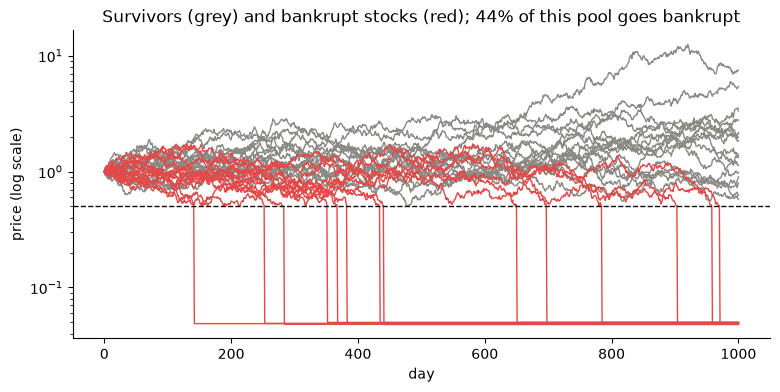

In [2]:
_, with_bankruptcy, rate = simulate(seed=0, sigma=0.03, T=1000, barrier=0.5, losses=[0.9])
S = with_bankruptcy[0.9]
dead = S.iloc[-1] < 0.5

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(S.loc[:, ~dead].iloc[:, :20], color="#8a8984", lw=1)
ax.plot(S.loc[:, dead].iloc[:, :20], color="#e34948", lw=1)
ax.axhline(0.5, color="#0b0b0b", lw=1, ls="--")
ax.set_yscale("log")
ax.set_xlabel("day")
ax.set_ylabel("price (log scale)")
ax.set_title(f"Survivors (grey) and bankrupt stocks (red); {rate:.0%} of this pool goes bankrupt")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Running the grid

To check that the answer doesn't hinge on one setting, the simulation runs over a grid of volatilities, horizons and barriers (12 settings) with 20 seeds each, and for two bankruptcy losses: 90% (a typical bankruptcy) and a milder 50%. Each setting and seed has its own pool of 2,000 stocks, 240 pools in all. The plain and survivor universes don't depend on the loss, so they are run once per pool, which makes 5,760 backtests. It takes about 2 minutes on a 10-core laptop.

In [3]:
SIGMAS, HORIZONS, BARRIERS, LOSSES, SEEDS = [0.02, 0.03], [500, 1000], [0.3, 0.5, 0.7], [0.9, 0.5], range(20)


def run_one(seed, sigma, T, barrier):
    # joblib runs this in separate processes, which don't inherit the settings above
    logging.disable(logging.CRITICAL)
    warnings.simplefilter("ignore")
    universes, with_bankruptcy, bankrupt_rate = simulate(seed, sigma, T, barrier, LOSSES)

    def log_wealth(S):
        return {name: np.log(A().run(S).total_wealth) for name, A in ALGOS.items()}

    shared = {universe: log_wealth(S) for universe, S in universes.items()}
    rows = []
    for loss in LOSSES:
        results = {**shared, "with bankruptcy": log_wealth(with_bankruptcy[loss])}
        rows += [
            dict(loss=loss, sigma=sigma, T=T, barrier=barrier, seed=seed, bankrupt_rate=bankrupt_rate,
                 universe=universe, algo=name, log_wealth=lw)
            for universe, lws in results.items()
            for name, lw in lws.items()
        ]
    return rows


grid = list(itertools.product(SEEDS, SIGMAS, HORIZONS, BARRIERS))
rows = Parallel(n_jobs=-1)(delayed(run_one)(*g) for g in grid)
df = pd.DataFrame([r for rs in rows for r in rs])

# log-wealth relative to uniform CRP on the same universe
setting = ["loss", "sigma", "T", "barrier"]
wide = df.pivot_table(index=setting + ["seed", "universe"], columns="algo", values="log_wealth")
excess = wide.sub(wide["CRP"], axis=0).drop(columns="CRP")
rate = df.groupby(setting)["bankrupt_rate"].mean().rename("bankrupt rate")

## Results

Final wealth relative to uniform CRP, averaged over all settings and seeds (the geometric mean, i.e. `exp` of the mean log-wealth difference). 100% means "same as CRP", so a value above 100% for buy-and-hold with bankruptcies means it loses less than CRP, not that it gains.

In [4]:
order = ["no bankruptcy", "survivors", "with bankruptcy"]
summary = np.exp(excess.groupby(["loss", "universe"]).mean()).T
summary = summary.reindex(columns=pd.MultiIndex.from_product([[0.9, 0.5], order]))
summary.style.format("{:.0%}")

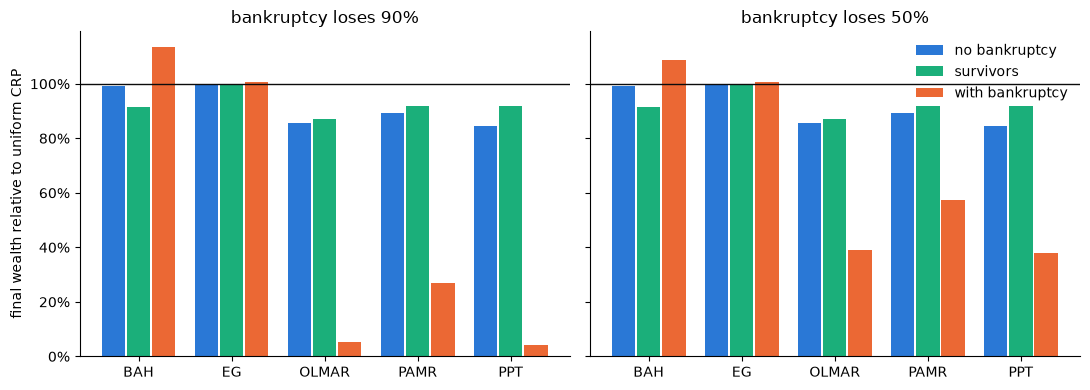

In [5]:
colors = {"no bankruptcy": "#2a78d6", "survivors": "#1baf7a", "with bankruptcy": "#eb6834"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, loss in zip(axes, [0.9, 0.5]):
    data = summary[loss]
    x = np.arange(len(data))
    for k, universe in enumerate(order):
        ax.bar(x + (k - 1) * 0.27, data[universe], width=0.25, color=colors[universe], label=universe)
    ax.axhline(1, color="#0b0b0b", lw=1)
    ax.set_xticks(x, data.index)
    ax.set_title(f"bankruptcy loses {loss:.0%}")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("final wealth relative to uniform CRP")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

Most of the grid has far more bankruptcies than a real market: at a barrier of 70%, 40–70% of the stocks go bankrupt within two to four years. The same comparison restricted to the settings where at most 10% of the stocks go bankrupt:

In [6]:
low = rate[rate <= 0.1].index
in_low = excess.index.droplevel(["seed", "universe"]).isin(low)
summary_low = np.exp(excess[in_low].groupby(["loss", "universe"]).mean()).T
summary_low = summary_low.reindex(columns=pd.MultiIndex.from_product([[0.9, 0.5], order]))
print(f"{len(low) // 2} settings, with {rate[low].min():.0%}-{rate[low].max():.0%} of the stocks going bankrupt")
summary_low.style.format("{:.0%}")

3 settings, with 1%-7% of the stocks going bankrupt


### Is it consistent across settings?

For each setting: how much better an algorithm does relative to CRP on survivors than on the universe with bankruptcies (difference in mean log-wealth, with a 95% interval over the 20 seeds). A positive value means survivor-only data makes the algorithm look better than it would be on a realistic universe.

In [7]:
stats = excess.stack().rename("excess").reset_index()
g = stats.groupby(setting + ["algo", "universe"])["excess"].agg(["mean", "var", "count"]).unstack("universe")
diff = g[("mean", "survivors")] - g[("mean", "with bankruptcy")]
se = np.sqrt(g[("var", "survivors")] / g[("count", "survivors")] + g[("var", "with bankruptcy")] / g[("count", "with bankruptcy")])
table = pd.DataFrame({"difference": diff, "lo": diff - 1.96 * se, "hi": diff + 1.96 * se})
table["sign"] = np.where(table.lo > 0, "better on survivors", np.where(table.hi < 0, "worse on survivors", "no clear difference"))

print(table.groupby(["loss", "algo"])["sign"].value_counts().unstack(fill_value=0).to_string())
table["difference"].unstack("algo").join(rate).round(2)

sign        better on survivors  no clear difference  worse on survivors
loss algo                                                               
0.5  BAH                      0                    1                  11
     EG                       0                    1                  11
     OLMAR                    6                    6                   0
     PAMR                     7                    5                   0
     PPT                      8                    4                   0
0.9  BAH                      0                    1                  11
     EG                       0                    1                  11
     OLMAR                    9                    3                   0
     PAMR                    10                    2                   0
     PPT                     12                    0                   0


BAH    EG  OLMAR  PAMR   PPT  bankrupt rate
loss sigma T    barrier                                              
0.5  0.02  500  0.3      0.00 -0.00   0.07  0.05  0.22           0.01
                0.5     -0.04 -0.00   0.25  0.07  0.18           0.12
                0.7     -0.12 -0.01   1.14  0.52  1.30           0.41
           1000 0.3     -0.06 -0.00   0.38  0.38  0.59           0.05
                0.5     -0.18 -0.01   0.39  0.38  0.10           0.27
                0.7     -0.22 -0.01   1.37  0.83  1.42           0.56
     0.03  500  0.3     -0.11 -0.01  -0.10 -0.05  0.18           0.07
                0.5     -0.16 -0.01   0.65  0.24  1.13           0.29
                0.7     -0.24 -0.01   1.62  1.25  1.65           0.58
           1000 0.3     -0.16 -0.01   0.26  0.25  0.39           0.19
                0.5     -0.38 -0.02   1.27  0.50  1.45           0.46
                0.7     -0.42 -0.02   2.33  1.23  1.99           0.69
0.9  0.02  500  0.3     -0.00 -0.00   0.07  0.05  0.22           0.01
                0.5     -0.07 -0.00   0.90  0.31  0.86           0.12
                0.7     -0.15 -0.01   3.96  1.58  4.44           0.41
           1000 0.3     -0.08 -0.01   0.75  0.45  0.97           0.05
                0.5     -0.24 -0.01   1.71  0.93  1.87           0.27
                0.7     -0.26 -0.01   5.00  2.32  5.20           0.56
     0.03  500  0.3     -0.13 -0.01   0.35 -0.00  0.96           0.07
                0.5     -0.22 -0.01   2.67  0.87  3.52           0.29
                0.7     -0.28 -0.01   5.90  2.93  6.01           0.58
           1000 0.3     -0.22 -0.02   1.13  0.47  1.31           0.19
                0.5     -0.48 -0.03   3.94  1.28  4.86           0.46
                0.7     -0.47 -0.02   7.65  3.55  6.77           0.69

## Conclusions

**Survivorship alone does not create the mean-reversion edge.** On random walks, OLMAR, PAMR and PPT end with 87–92% of uniform CRP's wealth on survivor-only data, close to where they are when nobody goes bankrupt (85–89%). Keeping only the survivors doesn't make them beat CRP. So in this model the selection can't explain the spectacular results these algorithms get on the benchmark datasets: OLMAR and PPT multiply wealth by about 10¹⁷–10¹⁸ on NYSE(O) before costs. Those results have to come from short-term reversal that is really in those historical prices. Whether that reversal could have been traded after costs and bid-ask spreads is a separate question.

**What survivorship does is hide the downside.** In a universe where stocks really go bankrupt, the same algorithms keep buying into the collapsing stocks:

- **Over the whole grid,** with a 90% bankruptcy loss, OLMAR and PPT end with about 5% of CRP's wealth and PAMR with 27%. With a 50% loss they end with 38–57%.
- **In the three settings closest to a real market,** where 1–7% of the stocks go bankrupt, they end with 46–76% of CRP's wealth at a 90% loss, against 84–94% on survivors.
- **Buy-and-hold and EG are not hurt.** Buy-and-hold even loses less than CRP once there are bankruptcies, because it never adds to a falling stock, while CRP rebalances into it.

The mean-reversion algorithms look better on survivors than on the universe with bankruptcies in 9–12 of the 12 settings with a 90% loss and in 6–8 with a 50% loss. They never look worse.

**Limits of this experiment.** Prices are independent random walks, bankruptcy is a simple barrier, every algorithm runs with its default parameters, and there are no transaction costs. It shows a mechanism, not the size of the effect on any real market.